<a href="https://colab.research.google.com/github/ChanceResearcher/skills-review-pull-requests/blob/main/GNR_PowerLaw_Task2_AreaUnderCurve.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import random
import matplotlib.pyplot as plt
from fractions import Fraction
from collections import Counter

#The same seed I saw the models using.
np.random.seed(12345)

In [2]:
def GNR_SimulationVm(NumNodes, alpha, r_probability):
    NumNodes += 1

    #Initialize the arrays for the simulation.

    # NodeConnections[i] will be a list of nodes that node i connects to.
    NodeConnections = [[] for _ in range(NumNodes)]

    #Number of nodes with k connections:
    #Index will be the Node ID, Column will be the node's connections.
    N_k_IN = np.zeros(NumNodes)
    N_k_OUT = np.zeros(NumNodes)
    N_k_Total = np.zeros(NumNodes)

    #Count of number of links per timestep / anode additions.
    Medges = np.zeros(NumNodes)
    Medges[2] = 2
    Out_per_timestep = 2

    #Initial Conditions: Node 1 connected to Node 2, Node 2 connected to Node 1.
    NodeConnections[1].append(2)
    NodeConnections[2].append(1)
    N_k_IN[1] = 1
    N_k_OUT[1] = 1
    N_k_Total[1] = 2
    N_k_IN[2] = 1
    N_k_OUT[2] = 1
    N_k_Total[2] = 2
    Medges[1] = 2
    Medges[2] = 2
    conflicts = 0
    totalLinks = 2

    #For each new node, randomly select a number of nodes to connect to,
    #out of a power law distribution.
    #Then, with probability r, connect to the ancestor of that node instead.

    for NodeID in range(3, NumNodes):
        # Determine possible values for 'm' (number of connections for the new node)
        # 'm' must be at least 1. Maximum 'm' can be NodeID - 1 (connections to all existing nodes).
        m_possible_values = np.arange(1, NodeID)

        # Calculate unnormalized probabilities based on the power law: P(m) ~ m^(-alpha)
        # Use the 'alpha' parameter passed to the GNR_SimulationVm function.
        unnormalized_probabilities_m = 1.0 / (m_possible_values ** alpha)

        # Normalize probabilities to sum to 1
        probabilities_m = unnormalized_probabilities_m / np.sum(unnormalized_probabilities_m)

        # Sample 'm' (the number of connections this new node will make
        m = np.random.choice(m_possible_values, p=probabilities_m)
        Medges[NodeID] = (2*m) + Medges[NodeID - 1]
        Out_per_timestep += m*(1/(m**(alpha)))
        for j in range(int(m)): # Ensure m is an integer for range
            NewNode = np.random.randint(1, NodeID)
            if random.random() < r_probability:
                randomAncestor = NodeConnections[NewNode][np.random.randint(0, len(NodeConnections[NewNode]))]
                NewNode = randomAncestor

            NodeConnections[NodeID].append(NewNode)

            totalLinks += 1
            N_k_IN[NewNode] += 1
            N_k_OUT[NodeID] += 1
            N_k_Total[NewNode] += 1
            N_k_Total[NodeID] += 1
        element_counts = Counter(NodeConnections[NodeID][:])
        conflicts += sum(freq - 1 for element, freq in element_counts.items() if freq > 1)

    return N_k_IN, N_k_OUT, N_k_Total, NodeConnections, Medges, Out_per_timestep, conflicts, totalLinks

In [3]:
# Proof of model working:

num_nodes = 10
alpha = 1
r = 0.3
trials = 1  # Increased trials for better statistical representation
conflictsToAverage = 0
TotalLinksToAverage = 0
for i in range(trials):
  N_k_IN, N_k_OUT, N_k_Total, NodeConnections, Medges, Out_per_timestep, conflicts, TotalLinks = GNR_SimulationVm(num_nodes, alpha, r)
  conflictsToAverage += conflicts
  TotalLinksToAverage += TotalLinks
conflictsAverage = conflictsToAverage/trials
TotalLinksAverage = TotalLinksToAverage/trials
print('Number of Conflicts: ', conflictsAverage)
print('Total Links: ', TotalLinksAverage)
print('Fraction of Conflicts of Total Links: ', conflictsAverage/TotalLinksAverage)
percentage_conflicts = (conflictsAverage / TotalLinksAverage) * 100
print(f"Percentage of redundant conflicts: {percentage_conflicts:.2f}%")
print("Nodes connected to: ", NodeConnections)


Number of Conflicts:  6.0
Total Links:  25.0
Fraction of Conflicts of Total Links:  0.24
Percentage of redundant conflicts: 24.00%
Nodes connected to:  [[], [2], [1], [2, 2], [2], [2, 2], [4, 2, 2, 1, 3], [6, 2, 2, 2, 6, 1], [2, 4], [2, 8, 4], [6, 8]]


alpha = 0, Percent Conflicts =  64.34760726816924
alpha = 0.5, Percent Conflicts =  62.67815409163635
alpha = 1, Percent Conflicts =  58.567356752397835
alpha = 1.5, Percent Conflicts =  49.163289925453924
alpha = 2, Percent Conflicts =  34.346235316772585
alpha = 2.5, Percent Conflicts =  20.378389890671585
alpha = 3, Percent Conflicts =  10.9567761590203
alpha = 3.5, Percent Conflicts =  5.854338878116815
alpha = 4, Percent Conflicts =  3.659506762132061
alpha = 4.5, Percent Conflicts =  2.147930995602661
alpha = 5, Percent Conflicts =  1.4349294045426642

Gaussian Fit Parameters:
  Amplitude (a): 63.19
  Mean (b): 0.44
  Standard Deviation (c): 1.36
  Offset (d): 1.14

Fitted Gaussian Equation: Percentage of Conflicts = 63.19 * exp(-((alpha - 0.44)^2) / (2 * 1.36^2)) + 1.14


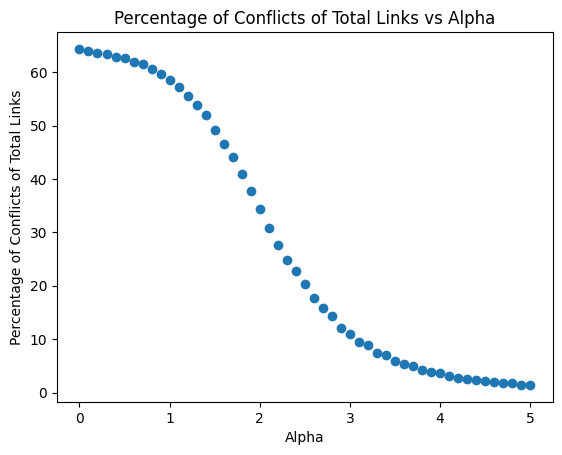

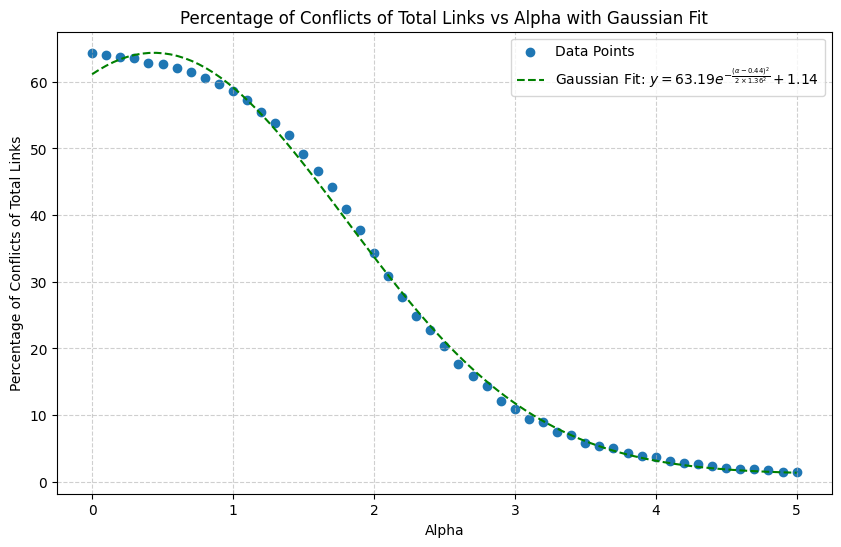

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

N = 100
r = 0.85
alphaMax = 5
trials = 500  # Increased trials for better statistical representation
alpha_PercentConflicts = np.zeros(alphaMax*10 + 1)
for alphaIndex in range (0, alphaMax*10 + 1):
  alpha_val = alphaIndex/10 # Renamed 'alpha' to 'alpha_val' to avoid conflict with function parameter
  conflictsToAverage = 0
  TotalLinksToAverage = 0
  for i in range(0,trials):
    N_k_IN, N_k_OUT, N_k_Total, NodeConnections, Medges, Out_per_timestep, conflicts, TotalLinks = GNR_SimulationVm(N, alpha_val, r)
    conflictsToAverage += conflicts
    TotalLinksToAverage += TotalLinks
  conflictsAverage = conflictsToAverage/trials
  TotalLinksAverage = TotalLinksToAverage/trials
  alpha_PercentConflicts[alphaIndex] = (conflictsAverage/TotalLinksAverage) * 100

alphaX = np.arange(0, alphaMax*10 + 1)/10

plt.figure()
plt.scatter(alphaX, alpha_PercentConflicts)
plt.xlabel('Alpha')
plt.ylabel('Percentage of Conflicts of Total Links')
plt.title('Percentage of Conflicts of Total Links vs Alpha')

print('alpha = 0, Percent Conflicts = ', alpha_PercentConflicts[0])
print('alpha = 0.5, Percent Conflicts = ', alpha_PercentConflicts[5])
print('alpha = 1, Percent Conflicts = ', alpha_PercentConflicts[10])
print('alpha = 1.5, Percent Conflicts = ', alpha_PercentConflicts[15])
print('alpha = 2, Percent Conflicts = ', alpha_PercentConflicts[20])
print('alpha = 2.5, Percent Conflicts = ', alpha_PercentConflicts[25])
print('alpha = 3, Percent Conflicts = ', alpha_PercentConflicts[30])
print('alpha = 3.5, Percent Conflicts = ', alpha_PercentConflicts[35])
print('alpha = 4, Percent Conflicts = ', alpha_PercentConflicts[40])
print('alpha = 4.5, Percent Conflicts = ', alpha_PercentConflicts[45])
print('alpha = 5, Percent Conflicts = ', alpha_PercentConflicts[50])

# --- Gaussian fitting code for alpha plot ---
# Define Gaussian function: y = a * exp(-((x - b)**2) / (2 * c**2)) + d
def gaussian(x, a, b, c, d):
    return a * np.exp(-((x - b)**2) / (2 * c**2)) + d

# Data for fitting
x_data = alphaX
y_data = alpha_PercentConflicts

# Initial guess for parameters: [amplitude (a), mean (b), std_dev (c), offset (d)]
# Allowing mean (b) to be determined by the fit
initial_guess_gaussian = [65, 0.5, 1.5, 0]

# Perform the Gaussian curve fit
popt_gaussian, pcov_gaussian = curve_fit(gaussian, x_data, y_data, p0=initial_guess_gaussian)
a_fit, b_fit, c_fit, d_fit = popt_gaussian

# Removed: b_fit = 0.0 to use the best-fit mean

print("\nGaussian Fit Parameters:")
print(f"  Amplitude (a): {a_fit:.2f}")
print(f"  Mean (b): {b_fit:.2f}")
print(f"  Standard Deviation (c): {c_fit:.2f}")
print(f"  Offset (d): {d_fit:.2f}")
print(f"\nFitted Gaussian Equation: Percentage of Conflicts = {a_fit:.2f} * exp(-((alpha - {b_fit:.2f})^2) / (2 * {c_fit:.2f}^2)) + {d_fit:.2f}")

# Generate points for the fitted curve for smooth plotting
alpha_fit_curve = np.linspace(min(x_data), max(x_data), 100)
gaussian_fit_values = gaussian(alpha_fit_curve, a_fit, b_fit, c_fit, d_fit)

# Plotting the Gaussian fit
plt.figure(figsize=(10, 6))
plt.scatter(x_data, y_data, label='Data Points')
plt.plot(alpha_fit_curve, gaussian_fit_values, color='green', linestyle='--', label=rf'Gaussian Fit: $y = {a_fit:.2f} e^{{-\frac{{(\alpha - {b_fit:.2f})^2}}{{2 \times {c_fit:.2f}^2}}}} + {d_fit:.2f}$'
)
plt.xlabel('Alpha')
plt.ylabel('Percentage of Conflicts of Total Links')
plt.title('Percentage of Conflicts of Total Links vs Alpha with Gaussian Fit')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

Gaussian Fit and Area Calculation for Percentage of Conflicts vs Alpha

In [5]:
import scipy.integrate as integrate
import math

# Define the Gaussian function using the fitted parameters
a_fit = popt_gaussian[0]
b_fit = popt_gaussian[1] # Using the best-fit mean from curve_fit
c_fit = popt_gaussian[2]
d_fit = popt_gaussian[3]

# The Gaussian function to integrate (excluding the offset d_fit for the main integral part)
def gaussian_no_offset(x, a, b, c):
    return a * np.exp(-((x - b)**2) / (2 * c**2))

# Define the integration limits (from 0 to alphaMax)
x_min = 0
x_max = alphaMax

# Calculate the integral of the Gaussian part (a * exp(...))
integral_gaussian_part, _ = integrate.quad(gaussian_no_offset, x_min, x_max, args=(a_fit, b_fit, c_fit))

# Calculate the integral of the offset part (d_fit)
integral_offset_part = d_fit * (x_max - x_min)

# Total area under the curve
total_area = integral_gaussian_part + integral_offset_part

print(f"Fitted Gaussian Equation (using best-fit mean): Percentage of Conflicts = {a_fit:.2f} * exp(-((alpha - {b_fit:.2f})^2) / (2 * {c_fit:.2f}^2)) + {d_fit:.2f}")
print(f"Area under the curve from alpha = {x_min} to {x_max}: {total_area:.2f}")


Fitted Gaussian Equation (using best-fit mean): Percentage of Conflicts = 63.19 * exp(-((alpha - 0.44)^2) / (2 * 1.36^2)) + 1.14
Area under the curve from alpha = 0 to 5: 140.36


### Polynomial Fit and Area Calculation for Percentage of Conflicts vs Alpha

Fitted Polynomial (degree 4):
         4         3         2
-0.6385 x + 8.081 x - 31.12 x + 21.53 x + 60.83

Area under the polynomial curve from alpha = 0 to 5: 140.37


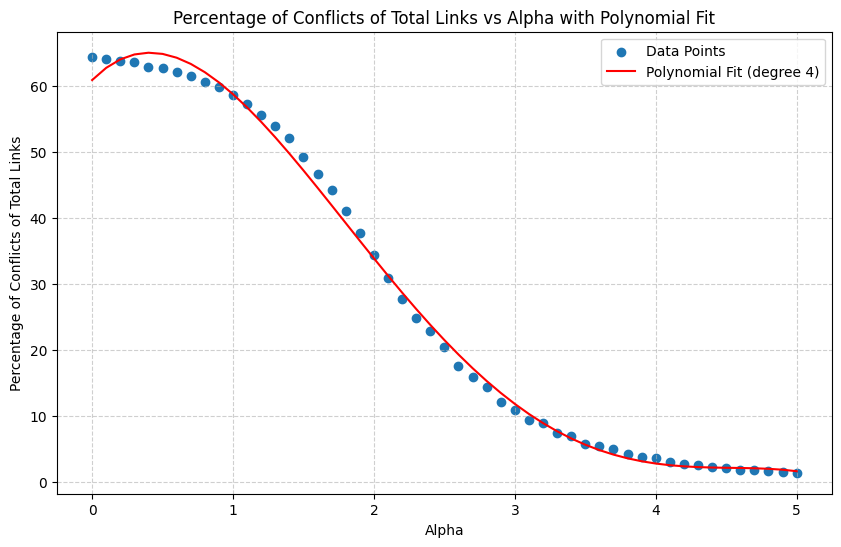

In [6]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.integrate as integrate

# Data from previous cells
x_data_poly = alphaX
y_data_poly = alpha_PercentConflicts

# Determine the degree of the polynomial. A 4th-degree polynomial seems reasonable for the curve shape.
degree = 4

# Fit a polynomial to the data
polynomial_coefficients = np.polyfit(x_data_poly, y_data_poly, degree)

# Create a polynomial function from the coefficients
poly_function = np.poly1d(polynomial_coefficients)

# Define the integration limits (from 0 to alphaMax, which is 5)
x_min_poly = 0
x_max_poly = alphaMax

# Calculate the integral of the polynomial function
area_poly_fit, _ = integrate.quad(poly_function, x_min_poly, x_max_poly)

print(f"Fitted Polynomial (degree {degree}):\n{poly_function}")
print(f"\nArea under the polynomial curve from alpha = {x_min_poly} to {x_max_poly}: {area_poly_fit:.2f}")

# Plotting the polynomial fit
plt.figure(figsize=(10, 6))
plt.scatter(x_data_poly, y_data_poly, label='Data Points')
plt.plot(x_data_poly, poly_function(x_data_poly), color='red', linestyle='-', label=f'Polynomial Fit (degree {degree})')
plt.xlabel('Alpha')
plt.ylabel('Percentage of Conflicts of Total Links')
plt.title('Percentage of Conflicts of Total Links vs Alpha with Polynomial Fit')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

### Area Calculation for Raw Data Points (Percentage of Conflicts vs Alpha)

In [7]:
import numpy as np

# Using the raw data arrays from the simulation
# x_data_raw = alphaX
# y_data_raw = alpha_PercentConflicts

# Calculate the area under the raw data curve using the trapezoidal rule
area_raw_data = np.trapz(alpha_PercentConflicts, alphaX)

print(f"Area under the raw data curve from alpha = {alphaX.min():.2f} to {alphaX.max():.2f}: {area_raw_data:.2f}")

Area under the raw data curve from alpha = 0.00 to 5.00: 140.18


/tmp/ipykernel_1048/2982226349.py:8: DeprecationWarning: `trapz` is deprecated. Use `trapezoid` instead, or one of the numerical integration functions in `scipy.integrate`.
  area_raw_data = np.trapz(alpha_PercentConflicts, alphaX)


Summary of Results

In [8]:
# Summary Of Results
print(f"Area under the Gaussian fit curve from alpha = {x_min} to {x_max}: {total_area:.2f}")
print(f"\nArea under the polynomial curve from alpha = {x_min_poly} to {x_max_poly}: {area_poly_fit:.2f}")
print(f"Area under the raw data curve from alpha = {alphaX.min():.2f} to {alphaX.max():.2f}: {area_raw_data:.2f}")

Area under the Gaussian fit curve from alpha = 0 to 5: 140.36

Area under the polynomial curve from alpha = 0 to 5: 140.37
Area under the raw data curve from alpha = 0.00 to 5.00: 140.18
